In [37]:
import pandas as pd

attributes = pd.read_csv("/home/s0shar47/scratch/RandomForestData/basin_attributes_531.csv")
nse = pd.read_csv("/home/s0shar47/scratch/RandomForestData/NSE_Furey_HBV.csv")

print(attributes.shape)
print(nse.shape)

print(attributes.columns)
print(nse.columns)

df = attributes.merge(
    nse,
    on="GAGE_ID",
    how="inner"
)
df= df.drop(columns={"NSE_old", 'NSE_improvement','Region_x', 'Region_y'})
print(df.shape)

(531, 37)
(531, 5)
Index(['GAGE_ID', 'p_mean', 'pet_mean', 'p_seasonality', 'frac_snow',
       'aridity', 'high_prec_freq', 'high_prec_dur', 'low_prec_freq',
       'low_prec_dur', 'elev_mean', 'slope_mean', 'area_gages2', 'frac_forest',
       'lai_max', 'lai_diff', 'gvf_max', 'gvf_diff', 'dom_land_cover_frac',
       'dom_land_cover', 'root_depth_50', 'soil_depth_pelletier',
       'soil_depth_statsgo', 'soil_porosity', 'soil_conductivity',
       'max_water_content', 'sand_frac', 'silt_frac', 'clay_frac',
       'geol_1st_class', 'glim_1st_class_frac', 'geol_2nd_class',
       'glim_2nd_class_frac', 'carbonate_rocks_frac', 'geol_porostiy',
       'geol_permeability', 'Region'],
      dtype='object')
Index(['GAGE_ID', 'Region', 'NSE_old', 'NSE_new', 'NSE_improvement'], dtype='object')
(531, 37)


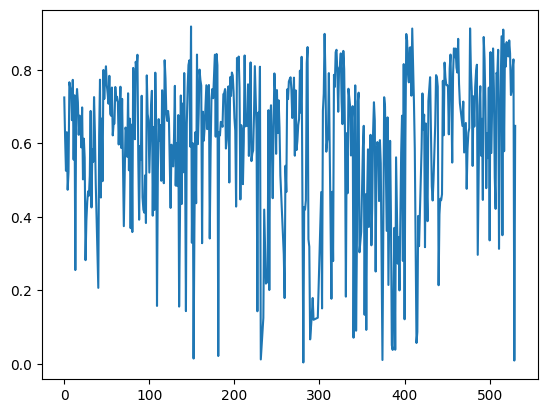

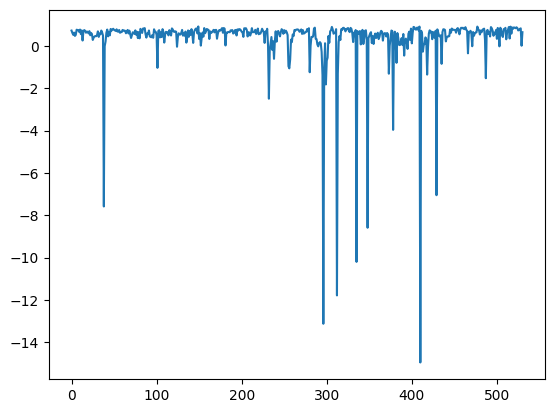

In [38]:
import matplotlib.pyplot as plt

plt.figure()
df[df["NSE_new"]>=0]['NSE_new'].plot()
plt.show()
# also check
plt.figure()
df.NSE_new.plot()
plt.show()

In [39]:
df.columns

Index(['GAGE_ID', 'p_mean', 'pet_mean', 'p_seasonality', 'frac_snow',
       'aridity', 'high_prec_freq', 'high_prec_dur', 'low_prec_freq',
       'low_prec_dur', 'elev_mean', 'slope_mean', 'area_gages2', 'frac_forest',
       'lai_max', 'lai_diff', 'gvf_max', 'gvf_diff', 'dom_land_cover_frac',
       'dom_land_cover', 'root_depth_50', 'soil_depth_pelletier',
       'soil_depth_statsgo', 'soil_porosity', 'soil_conductivity',
       'max_water_content', 'sand_frac', 'silt_frac', 'clay_frac',
       'geol_1st_class', 'glim_1st_class_frac', 'geol_2nd_class',
       'glim_2nd_class_frac', 'carbonate_rocks_frac', 'geol_porostiy',
       'geol_permeability', 'NSE_new'],
      dtype='object')

In [40]:
# Train data
X = df.drop(columns=["GAGE_ID", 'NSE_new'])

# set target
y = df["NSE_new"]

In [41]:
corr = df.select_dtypes("number").corr()["NSE_new"].sort_values()

print(corr)

aridity                -0.295408
low_prec_freq          -0.222860
high_prec_freq         -0.205363
p_seasonality          -0.161489
low_prec_dur           -0.138067
geol_permeability      -0.113413
soil_depth_pelletier   -0.099153
elev_mean              -0.097659
carbonate_rocks_frac   -0.092986
pet_mean               -0.092157
high_prec_dur          -0.073568
glim_1st_class_frac    -0.065192
area_gages2            -0.055316
geol_porostiy          -0.050673
geol_2nd_class         -0.045842
soil_conductivity      -0.045454
GAGE_ID                -0.038168
sand_frac              -0.030592
frac_snow              -0.029298
geol_1st_class         -0.015304
dom_land_cover         -0.000737
dom_land_cover_frac     0.009411
soil_depth_statsgo      0.015522
max_water_content       0.022186
soil_porosity           0.040719
silt_frac               0.052334
clay_frac               0.059754
glim_2nd_class_frac     0.062778
slope_mean              0.075108
gvf_diff                0.110267
root_depth

In [42]:
from sklearn.impute import SimpleImputer

##Handles nan if any
# print(X.isna().sum().sort_values(ascending=False))

imputer = SimpleImputer(strategy="median")
X_imp = imputer.fit_transform(X)

In [43]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

model = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=1.0))
])


In [44]:
from sklearn.model_selection import KFold, cross_val_score

cv = KFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

In [45]:
scores = cross_val_score(
    model,
    X_imp,
    y,
    cv=cv,
    scoring="r2"
)

print("R2:", scores.mean())
print("R2 std:", scores.std())

R2: -1.028445162857015
R2 std: 1.6494992981911942


In [46]:
import numpy as np

rmse_scores = -cross_val_score(
    model,
    X_imp,
    y,
    cv=cv,
    scoring="neg_root_mean_squared_error"
)

print("RMSE:", rmse_scores.mean())

RMSE: 1.2065734565054713


In [47]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(
    n_estimators=500,
    max_features="sqrt",
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

In [48]:
r2_scores = cross_val_score(
    rf,
    X_imp,
    y,
    cv=cv,
    scoring="r2"
)

rmse_scores = -cross_val_score(
    rf,
    X_imp,
    y,
    cv=cv,
    scoring="neg_root_mean_squared_error"
)

print("CV R2:", r2_scores.mean(), "+/-", r2_scores.std())
print("CV RMSE:", rmse_scores.mean(), "+/-", rmse_scores.std())

CV R2: -0.1585366455691171 +/- 0.5158549534249014
CV RMSE: 1.073694380849044 +/- 0.6653196724882005


In [32]:
from sklearn.inspection import permutation_importance

rf.fit(X_imp, y)

perm = permutation_importance(
    rf,
    X_imp,
    y,
    n_repeats=30,
    random_state=42,
    scoring="r2",
    n_jobs=-1
)

In [33]:
importance_df = pd.DataFrame({
    "attribute": X.columns,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std
})

importance_df = importance_df.sort_values(
    "importance_mean",
    ascending=False
)

print(importance_df)

               attribute  importance_mean  importance_std
0                 p_mean         0.071512        0.009339
12           frac_forest         0.056233        0.006358
4                aridity         0.044129        0.005675
13               lai_max         0.040391        0.004561
15               gvf_max         0.036479        0.004460
2          p_seasonality         0.036370        0.005718
5         high_prec_freq         0.021792        0.002291
14              lai_diff         0.020430        0.002806
19         root_depth_50         0.017302        0.002216
7          low_prec_freq         0.017208        0.002021
8           low_prec_dur         0.015706        0.001997
34     geol_permeability         0.015404        0.003264
29   glim_1st_class_frac         0.015082        0.004728
20  soil_depth_pelletier         0.014928        0.002915
31   glim_2nd_class_frac         0.014151        0.004251
27             clay_frac         0.013957        0.002665
9             

In [34]:
corr_matrix = X.corr()
import numpy as np

pairs = []

for i in range(len(corr_matrix.columns)):
    for j in range(i + 1, len(corr_matrix.columns)):
        r = corr_matrix.iloc[i, j]

        if abs(r) > 0.8:
            pairs.append((
                corr_matrix.columns[i],
                corr_matrix.columns[j],
                r
            ))

pairs

[('frac_snow', 'elev_mean', np.float64(0.8470254579954551)),
 ('high_prec_freq', 'low_prec_freq', np.float64(0.9012800088061508)),
 ('lai_max', 'lai_diff', np.float64(0.9337436533645258)),
 ('lai_max', 'gvf_max', np.float64(0.9359057432119761)),
 ('lai_diff', 'gvf_max', np.float64(0.8759554640547891)),
 ('soil_conductivity', 'sand_frac', np.float64(0.8093399975305274)),
 ('glim_1st_class_frac',
  'glim_2nd_class_frac',
  np.float64(-0.9004268768858156))]

count    531.000000
mean       0.370701
std        1.367634
min      -14.960291
25%        0.444617
50%        0.634501
75%        0.747031
max        0.918118
Name: NSE_new, dtype: float64


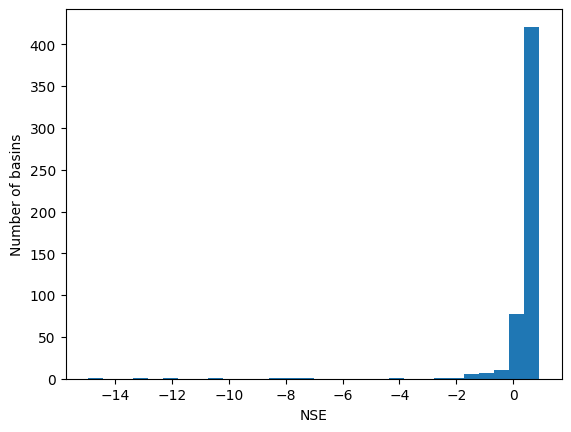

In [35]:
print(y.describe())

import matplotlib.pyplot as plt

plt.hist(y, bins=30)
plt.xlabel("NSE")
plt.ylabel("Number of basins")
plt.show()

DATA CHECK
Data shape: (531, 37)

Columns:
['GAGE_ID', 'p_mean', 'pet_mean', 'p_seasonality', 'frac_snow', 'aridity', 'high_prec_freq', 'high_prec_dur', 'low_prec_freq', 'low_prec_dur', 'elev_mean', 'slope_mean', 'area_gages2', 'frac_forest', 'lai_max', 'lai_diff', 'gvf_max', 'gvf_diff', 'dom_land_cover_frac', 'dom_land_cover', 'root_depth_50', 'soil_depth_pelletier', 'soil_depth_statsgo', 'soil_porosity', 'soil_conductivity', 'max_water_content', 'sand_frac', 'silt_frac', 'clay_frac', 'geol_1st_class', 'glim_1st_class_frac', 'geol_2nd_class', 'glim_2nd_class_frac', 'carbonate_rocks_frac', 'geol_porostiy', 'geol_permeability', 'NSE_new']

First 5 rows:
   GAGE_ID    p_mean  pet_mean  p_seasonality  frac_snow   aridity  \
0  1022500  3.608126  2.119256      -0.114530   0.245259  0.587356   
1  1031500  3.522957  2.071324       0.104091   0.291836  0.587950   
2  1047000  3.323146  2.090024       0.147776   0.280118  0.628929   
3  1052500  3.730858  2.096423       0.152097   0.352698  0

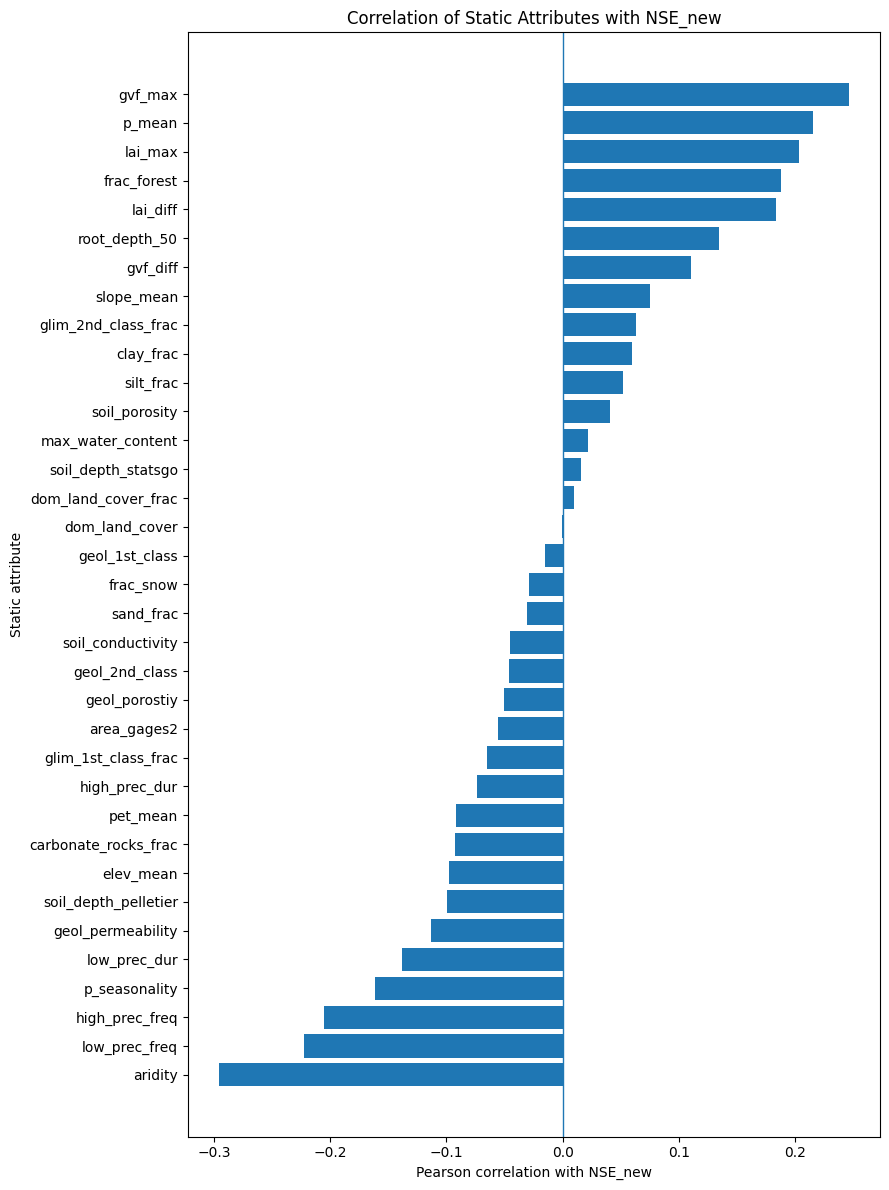


HIGHLY CORRELATED PREDICTOR PAIRS
lai_max                        gvf_max                         0.936
lai_max                        lai_diff                        0.934
high_prec_freq                 low_prec_freq                   0.901
glim_1st_class_frac            glim_2nd_class_frac            -0.900
lai_diff                       gvf_max                         0.876
frac_snow                      elev_mean                       0.847
soil_conductivity              sand_frac                       0.809

REPEATED CROSS-VALIDATION

Running: Dummy Mean

Running: Ridge

Running: Random Forest

Running: Extra Trees

         Model   R2_mean   R2_std  RMSE_mean  RMSE_std
   Dummy Mean -0.148698 0.348353   1.166401  0.716487
        Ridge -0.846610 1.711969   1.189115  0.587967
Random Forest -0.325740 1.144635   1.087034  0.614011
  Extra Trees -0.211884 0.942570   1.046447  0.617368

GENERATING OUT-OF-FOLD RF PREDICTIONS

Overall OOF RF performance
R2   = 0.1679
RMSE = 1.2464


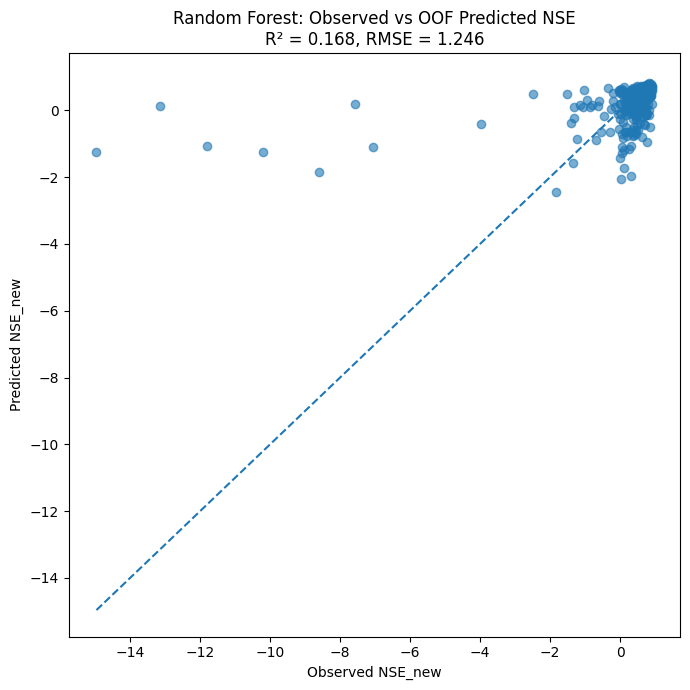


OUT-OF-FOLD PERMUTATION IMPORTANCE
Importance fold 1/50
Importance fold 2/50
Importance fold 3/50
Importance fold 4/50
Importance fold 5/50
Importance fold 6/50
Importance fold 7/50
Importance fold 8/50
Importance fold 9/50
Importance fold 10/50
Importance fold 11/50
Importance fold 12/50
Importance fold 13/50
Importance fold 14/50
Importance fold 15/50
Importance fold 16/50
Importance fold 17/50
Importance fold 18/50
Importance fold 19/50
Importance fold 20/50
Importance fold 21/50
Importance fold 22/50
Importance fold 23/50
Importance fold 24/50
Importance fold 25/50
Importance fold 26/50
Importance fold 27/50
Importance fold 28/50
Importance fold 29/50
Importance fold 30/50
Importance fold 31/50
Importance fold 32/50
Importance fold 33/50
Importance fold 34/50
Importance fold 35/50
Importance fold 36/50
Importance fold 37/50
Importance fold 38/50
Importance fold 39/50
Importance fold 40/50
Importance fold 41/50
Importance fold 42/50
Importance fold 43/50
Importance fold 44/50
Impor

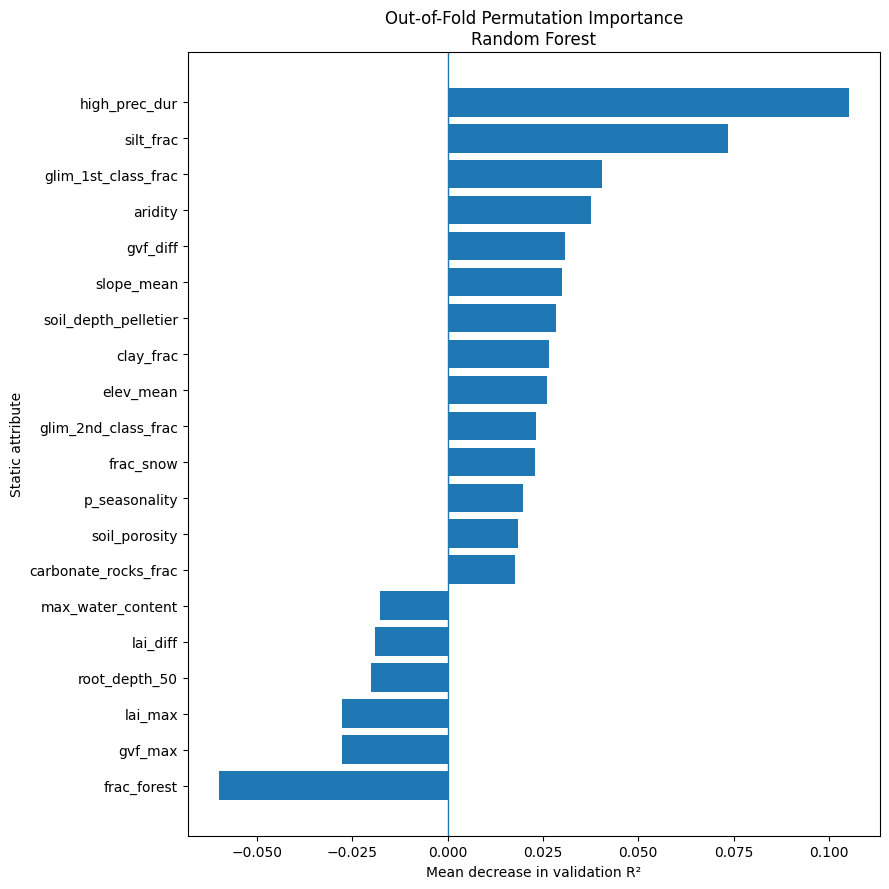


FINAL ATTRIBUTE ANALYSIS
           attribute   pearson  spearman  importance_mean  importance_std  importance_median  rank
       high_prec_dur -0.073568 -0.134609         0.105160        0.208713           0.013627     1
           silt_frac  0.052334  0.218806         0.073512        0.124381           0.015399     2
         frac_forest  0.188125  0.250385        -0.059905        0.227037           0.010154     3
 glim_1st_class_frac -0.065192 -0.093447         0.040389        0.096960           0.012757     4
             aridity -0.295408 -0.342291         0.037596        0.110036           0.023818     5
            gvf_diff  0.110267  0.052598         0.030775        0.066844           0.004283     6
          slope_mean  0.075108  0.171036         0.029924        0.051804           0.005740     7
soil_depth_pelletier -0.099153 -0.061433         0.028527        0.047894           0.013583     8
             gvf_max  0.246051  0.271817        -0.027850        0.129918          

In [49]:
# ============================================================
# STATIC ATTRIBUTE INFLUENCE ON NSE_new
#
# Goal:
#   Determine which static basin attributes are associated with
#   spatial variability in NSE_new using shallow ML.
#
# Models:
#   1. DummyRegressor
#   2. Ridge Regression
#   3. Random Forest
#   4. Extra Trees
#
# Validation:
#   Repeated 10-fold cross-validation
#
# Feature importance:
#   Out-of-fold permutation importance
#
# IMPORTANT:
#   df already contains:
#       - GAGE_ID
#       - static attributes
#       - NSE_new
#
#   Already removed:
#       - NSE_old
#       - NSE_improvement
#       - Region_x
#       - Region_y
#
# ============================================================


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import RepeatedKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import ExtraTreesRegressor

from sklearn.metrics import (
    r2_score,
    mean_squared_error
)

from sklearn.inspection import permutation_importance


# ============================================================
# 2. SETTINGS
# ============================================================

TARGET = "NSE_new"
ID_COL = "GAGE_ID"

RANDOM_STATE = 111111

N_SPLITS = 10
N_REPEATS = 5

# Number of trees
N_ESTIMATORS = 500

# Number of permutations for final importance
N_PERMUTATIONS = 30


# ============================================================
# 3. BASIC DATA CHECK
# ============================================================

print("=" * 70)
print("DATA CHECK")
print("=" * 70)

print("Data shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
print(df.head())

print("\nMissing values:")
print(df.isnull().sum().sort_values(ascending=False).head(20))


# ============================================================
# 4. CHECK GAGE IDS
# ============================================================

print("\n" + "=" * 70)
print("GAGE CHECK")
print("=" * 70)

if ID_COL in df.columns:

    print("Number of rows:", len(df))
    print("Unique GAGE_ID:", df[ID_COL].nunique())

    duplicate_gages = df[ID_COL].duplicated().sum()

    print("Duplicate GAGE_ID rows:", duplicate_gages)

else:

    print("WARNING: GAGE_ID not found.")


# ============================================================
# 5. CHECK TARGET
# ============================================================

print("\n" + "=" * 70)
print("TARGET CHECK")
print("=" * 70)

print(df[TARGET].describe())

print("\nNumber of NaN NSE:", df[TARGET].isna().sum())

print("\nNumber of NSE < 0:",
      (df[TARGET] < 0).sum())

print("Number of NSE < -1:",
      (df[TARGET] < -1).sum())

print("Number of NSE < -2:",
      (df[TARGET] < -2).sum())

print("Number of NSE < -5:",
      (df[TARGET] < -5).sum())

print("Number of NSE < -10:",
      (df[TARGET] < -10).sum())


# ============================================================
# 6. IDENTIFY EXTREME NSE BASINS
# ============================================================

print("\n" + "=" * 70)
print("LOWEST NSE BASINS")
print("=" * 70)

cols_to_show = [c for c in [ID_COL, TARGET] if c in df.columns]

lowest_nse = (
    df[cols_to_show]
    .sort_values(TARGET)
    .head(20)
)

print(lowest_nse.to_string(index=False))


# ============================================================
# 7. REMOVE ROWS WITH MISSING TARGET
# ============================================================

data = df.copy()

data = data.dropna(subset=[TARGET]).reset_index(drop=True)

print("\nRows after removing missing NSE:", len(data))


# ============================================================
# 8. DEFINE FEATURES AND TARGET
# ============================================================

# Remove ID from predictors.
#
# GAGE_ID is an identifier and has no physical meaning.
# Including it can create meaningless splits in tree models.

drop_columns = [
    TARGET,
    ID_COL
]

feature_columns = [
    c for c in data.columns
    if c not in drop_columns
]


X = data[feature_columns].copy()
y = data[TARGET].copy()


# ============================================================
# 9. MAKE SURE FEATURES ARE NUMERIC
# ============================================================

print("\n" + "=" * 70)
print("FEATURE TYPES")
print("=" * 70)

non_numeric = X.select_dtypes(
    exclude=[np.number]
).columns.tolist()

print("Non-numeric columns:")

if len(non_numeric) == 0:
    print("None")
else:
    print(non_numeric)


# If categorical columns exist, this code stops rather than
# silently doing something inappropriate.

if len(non_numeric) > 0:

    raise ValueError(
        "Non-numeric predictor columns found: "
        + str(non_numeric)
        + "\nHandle these categorical variables before continuing."
    )


print("\nNumber of predictor attributes:", X.shape[1])

print("\nPredictors:")
print(feature_columns)


# ============================================================
# 10. CORRELATION ANALYSIS
# ============================================================

print("\n" + "=" * 70)
print("CORRELATION WITH NSE_new")
print("=" * 70)

correlation_results = []

for col in feature_columns:

    pearson = X[col].corr(y, method="pearson")
    spearman = X[col].corr(y, method="spearman")

    correlation_results.append(
        {
            "attribute": col,
            "pearson": pearson,
            "spearman": spearman,
            "abs_pearson": abs(pearson),
            "abs_spearman": abs(spearman)
        }
    )


correlation_df = pd.DataFrame(
    correlation_results
)

correlation_df = (
    correlation_df
    .sort_values("abs_spearman", ascending=False)
    .reset_index(drop=True)
)

print(
    correlation_df[
        [
            "attribute",
            "pearson",
            "spearman"
        ]
    ].to_string(index=False)
)


# ============================================================
# 11. PLOT CORRELATIONS
# ============================================================

plot_corr = (
    correlation_df
    .sort_values("pearson")
)

plt.figure(figsize=(9, 12))

plt.barh(
    plot_corr["attribute"],
    plot_corr["pearson"]
)

plt.axvline(
    0,
    linewidth=1
)

plt.xlabel("Pearson correlation with NSE_new")
plt.ylabel("Static attribute")
plt.title("Correlation of Static Attributes with NSE_new")

plt.tight_layout()
plt.show()


# ============================================================
# 12. CHECK HIGHLY CORRELATED PREDICTORS
# ============================================================

print("\n" + "=" * 70)
print("HIGHLY CORRELATED PREDICTOR PAIRS")
print("=" * 70)

corr_matrix = X.corr()

high_corr_pairs = []

for i in range(len(corr_matrix.columns)):

    for j in range(i + 1, len(corr_matrix.columns)):

        col1 = corr_matrix.columns[i]
        col2 = corr_matrix.columns[j]

        corr_value = corr_matrix.iloc[i, j]

        if abs(corr_value) >= 0.80:

            high_corr_pairs.append(
                (
                    col1,
                    col2,
                    corr_value
                )
            )


high_corr_pairs = sorted(
    high_corr_pairs,
    key=lambda x: abs(x[2]),
    reverse=True
)


for pair in high_corr_pairs:

    print(
        f"{pair[0]:30s} "
        f"{pair[1]:30s} "
        f"{pair[2]: .3f}"
    )


# ============================================================
# 13. CROSS-VALIDATION SETUP
# ============================================================

cv = RepeatedKFold(
    n_splits=N_SPLITS,
    n_repeats=N_REPEATS,
    random_state=RANDOM_STATE
)


# ============================================================
# 14. DEFINE MODELS
# ============================================================

models = {

    "Dummy Mean": Pipeline(
        steps=[
            (
                "imputer",
                SimpleImputer(strategy="median")
            ),

            (
                "model",
                DummyRegressor(
                    strategy="mean"
                )
            )
        ]
    ),

    "Ridge": Pipeline(
        steps=[
            (
                "imputer",
                SimpleImputer(strategy="median")
            ),

            (
                "scaler",
                StandardScaler()
            ),

            (
                "model",
                Ridge(
                    alpha=10.0
                )
            )
        ]
    ),

    "Random Forest": Pipeline(
        steps=[
            (
                "imputer",
                SimpleImputer(strategy="median")
            ),

            (
                "model",
                RandomForestRegressor(
                    n_estimators=N_ESTIMATORS,
                    random_state=RANDOM_STATE,
                    n_jobs=-1,
                    max_features="sqrt",
                    min_samples_leaf=3
                )
            )
        ]
    ),

    "Extra Trees": Pipeline(
        steps=[
            (
                "imputer",
                SimpleImputer(strategy="median")
            ),

            (
                "model",
                ExtraTreesRegressor(
                    n_estimators=N_ESTIMATORS,
                    random_state=RANDOM_STATE,
                    n_jobs=-1,
                    max_features=1.0,
                    min_samples_leaf=3
                )
            )
        ]
    )
}


# ============================================================
# 15. CROSS-VALIDATED MODEL COMPARISON
# ============================================================

print("\n" + "=" * 70)
print("REPEATED CROSS-VALIDATION")
print("=" * 70)

model_results = []


for model_name, model in models.items():

    print(f"\nRunning: {model_name}")

    r2_scores = []
    rmse_scores = []

    for fold, (train_idx, test_idx) in enumerate(cv.split(X), 1):

        X_train = X.iloc[train_idx]
        X_test = X.iloc[test_idx]

        y_train = y.iloc[train_idx]
        y_test = y.iloc[test_idx]

        model.fit(
            X_train,
            y_train
        )

        pred = model.predict(
            X_test
        )

        r2 = r2_score(
            y_test,
            pred
        )

        rmse = np.sqrt(
            mean_squared_error(
                y_test,
                pred
            )
        )

        r2_scores.append(r2)
        rmse_scores.append(rmse)

    model_results.append(
        {
            "Model": model_name,

            "R2_mean": np.mean(r2_scores),
            "R2_std": np.std(r2_scores),

            "RMSE_mean": np.mean(rmse_scores),
            "RMSE_std": np.std(rmse_scores)
        }
    )


model_results_df = pd.DataFrame(
    model_results
)

print(
    "\n",
    model_results_df.to_string(index=False)
)


# ============================================================
# 16. SELECT RANDOM FOREST FOR FEATURE IMPORTANCE
# ============================================================

rf_model = models["Random Forest"]


# ============================================================
# 17. OUT-OF-FOLD PREDICTIONS
# ============================================================

print("\n" + "=" * 70)
print("GENERATING OUT-OF-FOLD RF PREDICTIONS")
print("=" * 70)

oof_predictions = np.full(
    len(y),
    np.nan
)

fold_number = np.zeros(
    len(y),
    dtype=int
)


for fold, (train_idx, test_idx) in enumerate(
    cv.split(X),
    1
):

    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]

    y_train = y.iloc[train_idx]

    rf_model.fit(
        X_train,
        y_train
    )

    pred = rf_model.predict(
        X_test
    )

    oof_predictions[test_idx] = pred
    fold_number[test_idx] = fold


# ============================================================
# 18. OOF PERFORMANCE
# ============================================================

oof_valid = ~np.isnan(
    oof_predictions
)

oof_r2 = r2_score(
    y.iloc[oof_valid],
    oof_predictions[oof_valid]
)

oof_rmse = np.sqrt(
    mean_squared_error(
        y.iloc[oof_valid],
        oof_predictions[oof_valid]
    )
)

print("\nOverall OOF RF performance")

print(
    f"R2   = {oof_r2:.4f}"
)

print(
    f"RMSE = {oof_rmse:.4f}"
)


# ============================================================
# 19. OBSERVED VS PREDICTED NSE
# ============================================================

plt.figure(figsize=(7, 7))

plt.scatter(
    y.iloc[oof_valid],
    oof_predictions[oof_valid],
    alpha=0.6
)

min_value = min(
    y.iloc[oof_valid].min(),
    oof_predictions[oof_valid].min()
)

max_value = max(
    y.iloc[oof_valid].max(),
    oof_predictions[oof_valid].max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Observed NSE_new")
plt.ylabel("Predicted NSE_new")

plt.title(
    f"Random Forest: Observed vs OOF Predicted NSE\n"
    f"R² = {oof_r2:.3f}, RMSE = {oof_rmse:.3f}"
)

plt.tight_layout()
plt.show()


# ============================================================
# 20. OUT-OF-FOLD PERMUTATION IMPORTANCE
#
# IMPORTANT:
#
# We calculate importance on validation data rather than
# training data.
#
# This is much more defensible for your study because the
# question is:
#
# "How much does the predictive performance deteriorate
#  when this attribute is destroyed in unseen basins?"
#
# ============================================================

print("\n" + "=" * 70)
print("OUT-OF-FOLD PERMUTATION IMPORTANCE")
print("=" * 70)


importance_records = []


# Use a separate KFold for importance
# because we want each basin to receive an importance
# estimate from data where it was not used for fitting.

importance_cv = RepeatedKFold(
    n_splits=10,
    n_repeats=5,
    random_state=RANDOM_STATE
)


for fold, (train_idx, test_idx) in enumerate(
    importance_cv.split(X),
    1
):

    print(
        f"Importance fold {fold}/"
        f"{10 * 5}"
    )

    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]

    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    rf_model.fit(
        X_train,
        y_train
    )

    result = permutation_importance(
        rf_model,
        X_test,
        y_test,

        n_repeats=N_PERMUTATIONS,

        random_state=RANDOM_STATE + fold,

        scoring="r2",

        n_jobs=-1
    )

    for i, attribute in enumerate(
        feature_columns
    ):

        importance_records.append(
            {
                "fold": fold,

                "attribute": attribute,

                "importance": result.importances_mean[i]
            }
        )


importance_long = pd.DataFrame(
    importance_records
)


# ============================================================
# 21. SUMMARIZE PERMUTATION IMPORTANCE
# ============================================================

importance_summary = (
    importance_long
    .groupby("attribute")
    .agg(
        importance_mean=(
            "importance",
            "mean"
        ),

        importance_std=(
            "importance",
            "std"
        ),

        importance_median=(
            "importance",
            "median"
        )
    )
    .reset_index()
)


importance_summary[
    "abs_importance"
] = importance_summary[
    "importance_mean"
].abs()


importance_summary = (
    importance_summary
    .sort_values(
        "abs_importance",
        ascending=False
    )
    .reset_index(drop=True)
)


importance_summary[
    "rank"
] = np.arange(
    1,
    len(importance_summary) + 1
)


print("\nFinal OOF permutation importance:")

print(
    importance_summary[
        [
            "rank",
            "attribute",
            "importance_mean",
            "importance_std",
            "importance_median"
        ]
    ].to_string(index=False)
)


# ============================================================
# 22. PLOT PERMUTATION IMPORTANCE
# ============================================================

top_n = 20

plot_importance = (
    importance_summary
    .head(top_n)
    .sort_values(
        "importance_mean"
    )
)


plt.figure(
    figsize=(9, 9)
)

plt.barh(
    plot_importance["attribute"],
    plot_importance["importance_mean"]
)

plt.axvline(
    0,
    linewidth=1
)

plt.xlabel(
    "Mean decrease in validation R²"
)

plt.ylabel(
    "Static attribute"
)

plt.title(
    "Out-of-Fold Permutation Importance\n"
    "Random Forest"
)

plt.tight_layout()
plt.show()


# ============================================================
# 23. CORRELATION + ML IMPORTANCE TABLE
# ============================================================

final_attribute_table = (
    correlation_df[
        [
            "attribute",
            "pearson",
            "spearman"
        ]
    ]
    .merge(
        importance_summary[
            [
                "attribute",
                "importance_mean",
                "importance_std",
                "importance_median",
                "rank"
            ]
        ],
        on="attribute",
        how="left"
    )
)


final_attribute_table = (
    final_attribute_table
    .sort_values(
        "rank"
    )
    .reset_index(drop=True)
)


print("\n" + "=" * 70)
print("FINAL ATTRIBUTE ANALYSIS")
print("=" * 70)

print(
    final_attribute_table.to_string(
        index=False
    )
)


# ============================================================
# 24. TOP 15 ATTRIBUTES
# ============================================================

print("\n" + "=" * 70)
print("TOP 15 ATTRIBUTES")
print("=" * 70)

print(
    final_attribute_table
    .head(15)
    .to_string(index=False)
)


# ============================================================
# 25. IDENTIFY ATTRIBUTES WITH NEGATIVE PERMUTATION IMPORTANCE
# ============================================================

negative_importance = (
    importance_summary[
        importance_summary["importance_mean"] < 0
    ]
    .sort_values(
        "importance_mean"
    )
)


print("\n" + "=" * 70)
print("NEGATIVE MEAN PERMUTATION IMPORTANCE")
print("=" * 70)

print(
    negative_importance[
        [
            "attribute",
            "importance_mean",
            "importance_std"
        ]
    ].to_string(index=False)
)


# ============================================================
# 26. MODEL FEATURE IMPORTANCE FROM FINAL RF
#
# This is included only for comparison.
#
# DO NOT use this as your primary importance measure because
# impurity-based RF importance can be misleading when
# predictors are correlated.
# ============================================================

rf_model.fit(
    X,
    y
)

impurity_importance = pd.DataFrame(
    {
        "attribute": feature_columns,
        "impurity_importance":
            rf_model.named_steps[
                "model"
            ].feature_importances_
    }
)

impurity_importance = (
    impurity_importance
    .sort_values(
        "impurity_importance",
        ascending=False
    )
    .reset_index(drop=True)
)


print("\n" + "=" * 70)
print("RF IMPURITY IMPORTANCE")
print("=" * 70)

print(
    impurity_importance.head(20)
    .to_string(index=False)
)


# ============================================================
# 27. TOP ATTRIBUTE CORRELATION WITH NSE
# ============================================================

print("\n" + "=" * 70)
print("TOP ATTRIBUTES BY ABSOLUTE SPEARMAN CORRELATION")
print("=" * 70)

print(
    correlation_df[
        [
            "attribute",
            "pearson",
            "spearman"
        ]
    ]
    .head(15)
    .to_string(index=False)
)


# ============================================================
# 28. OPTIONAL: PERFORMANCE GROUPS
#
# This is useful for understanding whether the attributes
# differ between high-, moderate-, poor-, and negative-NSE
# basins.
#
# DO NOT use these groups as the primary ML target.
# ============================================================

data["NSE_group"] = pd.cut(
    data[TARGET],

    bins=[
        -np.inf,
        0,
        0.3,
        0.7,
        np.inf
    ],

    labels=[
        "NSE < 0",
        "0 <= NSE < 0.3",
        "0.3 <= NSE < 0.7",
        "NSE >= 0.7"
    ]
)


print("\n" + "=" * 70)
print("NSE PERFORMANCE GROUPS")
print("=" * 70)

print(
    data["NSE_group"]
    .value_counts()
    .sort_index()
)


# ============================================================
# 29. ATTRIBUTE MEANS BY NSE GROUP
# ============================================================

group_attribute_means = (
    data
    .groupby(
        "NSE_group",
        observed=True
    )[feature_columns]
    .mean()
)


print("\n" + "=" * 70)
print("ATTRIBUTE MEANS BY NSE GROUP")
print("=" * 70)

print(
    group_attribute_means
    .T
    .to_string()
)


# ============================================================
# 30. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("FINAL SUMMARY")
print("=" * 70)

print(
    f"Number of basins: {len(data)}"
)

print(
    f"Number of static attributes: {len(feature_columns)}"
)

print(
    f"Repeated CV: {N_SPLITS}-fold × {N_REPEATS} repeats"
)

print(
    f"OOF Random Forest R²: {oof_r2:.4f}"
)

print(
    f"OOF Random Forest RMSE: {oof_rmse:.4f}"
)

print("\nTop 10 attributes by OOF permutation importance:")

print(
    importance_summary[
        [
            "attribute",
            "importance_mean",
            "importance_std"
        ]
    ]
    .head(10)
    .to_string(index=False)
)


# ============================================================
# OPTIONAL SAVE COMMANDS
#
# Nothing is saved by default.
#
# Uncomment only if you want CSV files.
# ============================================================

# final_attribute_table.to_csv(
#     "NSE_new_static_attribute_analysis.csv",
#     index=False
# )

# importance_summary.to_csv(
#     "NSE_new_permutation_importance.csv",
#     index=False
# )

# model_results_df.to_csv(
#     "NSE_new_model_comparison.csv",
#     index=False
# )


STATIC ATTRIBUTE INFLUENCE ANALYSIS

DATASET SHAPE
--------------------------------------------------------------------------------
(531, 37)

MISSING VALUES
--------------------------------------------------------------------------------
Series([], dtype: int64)
No missing values.

FINAL DATASET
--------------------------------------------------------------------------------
Number of basins: 531
Number of predictors: 35

NSE_NEW DISTRIBUTION
count    531.000000
mean       0.370701
std        1.367634
min      -14.960291
1%        -7.428056
5%        -0.404085
25%        0.444617
50%        0.634501
75%        0.747031
95%        0.844078
99%        0.895792
max        0.918118
Name: NSE_new, dtype: float64

Negative NSE counts
--------------------------------------------------------------------------------
NSE < 0 : 39
NSE < -1: 19
NSE < -2: 9
NSE < -5: 7
NSE < -10: 4

Lowest NSE basins
--------------------------------------------------------------------------------
      GAGE_ID   

<Figure size 800x500 with 0 Axes>

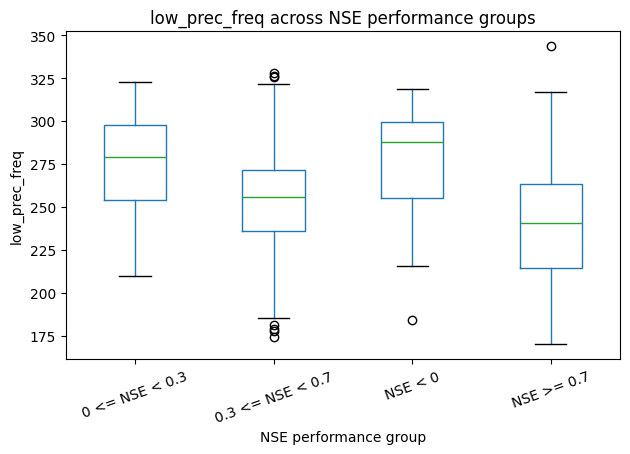

<Figure size 800x500 with 0 Axes>

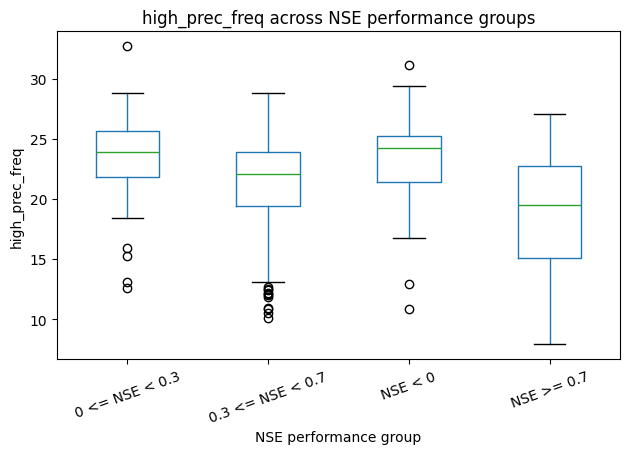

<Figure size 800x500 with 0 Axes>

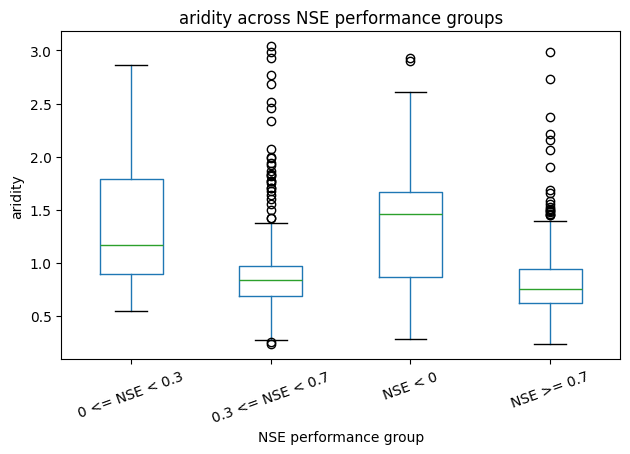

<Figure size 800x500 with 0 Axes>

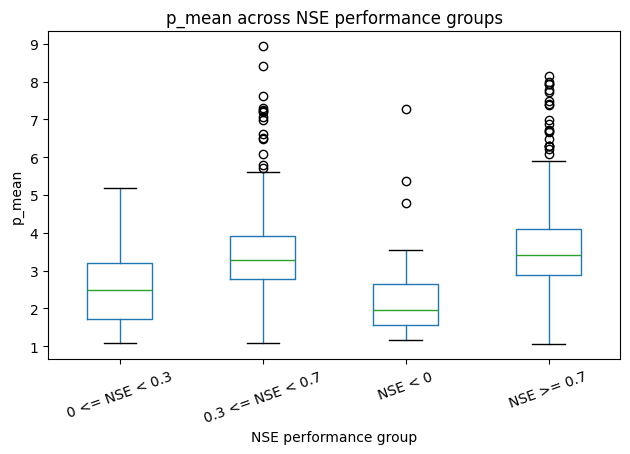

<Figure size 800x500 with 0 Axes>

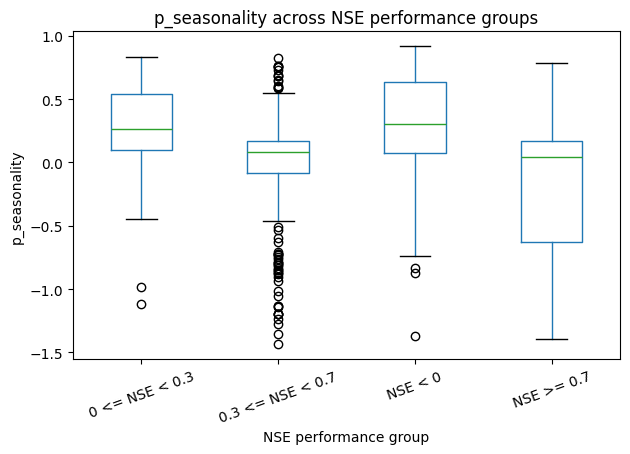

<Figure size 800x500 with 0 Axes>

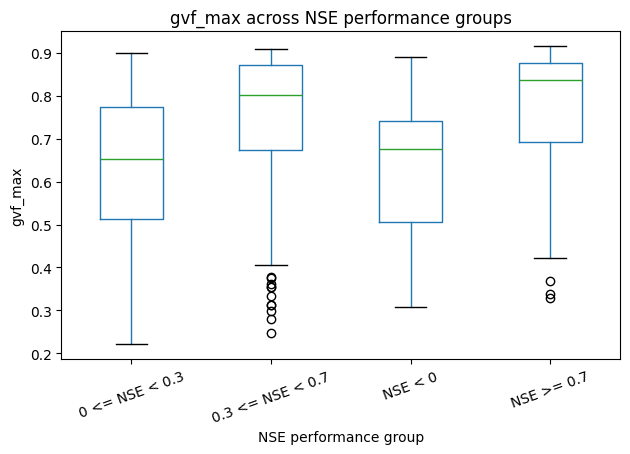

<Figure size 800x500 with 0 Axes>

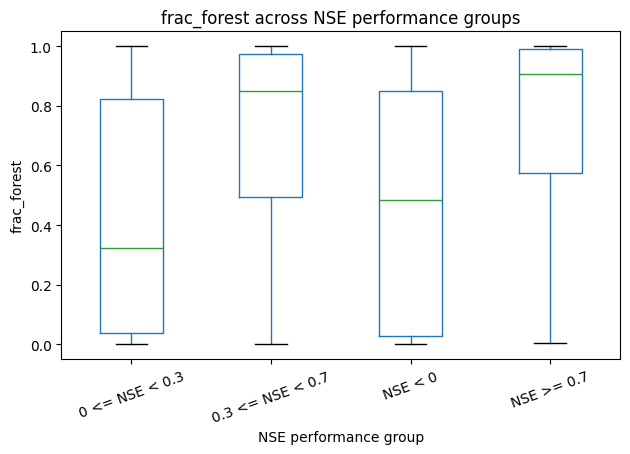

<Figure size 800x500 with 0 Axes>

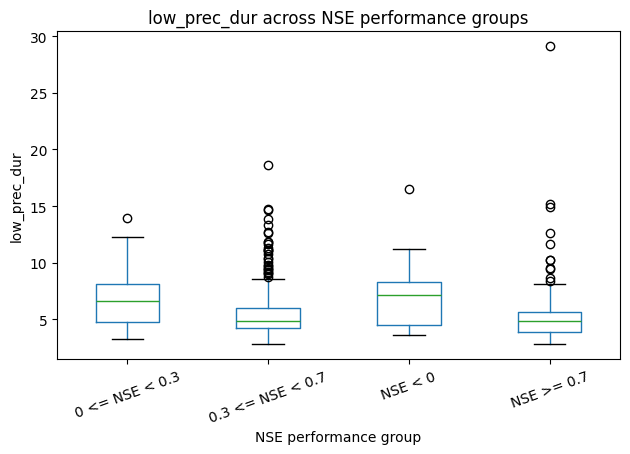


NSE PERFORMANCE CLASSIFICATION

Class counts
--------------------------------------------------------------------------------
NSE < 0: 39
0 <= NSE < 0.3: 46
0.3 <= NSE < 0.7: 254
NSE >= 0.7: 192
      Accuracy  Balanced_Accuracy  Macro_F1
mean  0.610238           0.464729  0.476205
std   0.073964           0.088249  0.104577

Pooled classification performance
--------------------------------------------------------------------------------
Accuracy: 0.6101694915254238
Balanced accuracy: 0.4644730096055092
Macro F1: 0.47237451666552993

Confusion matrix
--------------------------------------------------------------------------------
                  NSE < 0  0 <= NSE < 0.3  0.3 <= NSE < 0.7  NSE >= 0.7
NSE < 0                14               9                11           5
0 <= NSE < 0.3         10               7                23           6
0.3 <= NSE < 0.7        9              14               182          49
NSE >= 0.7              1               1                69         121


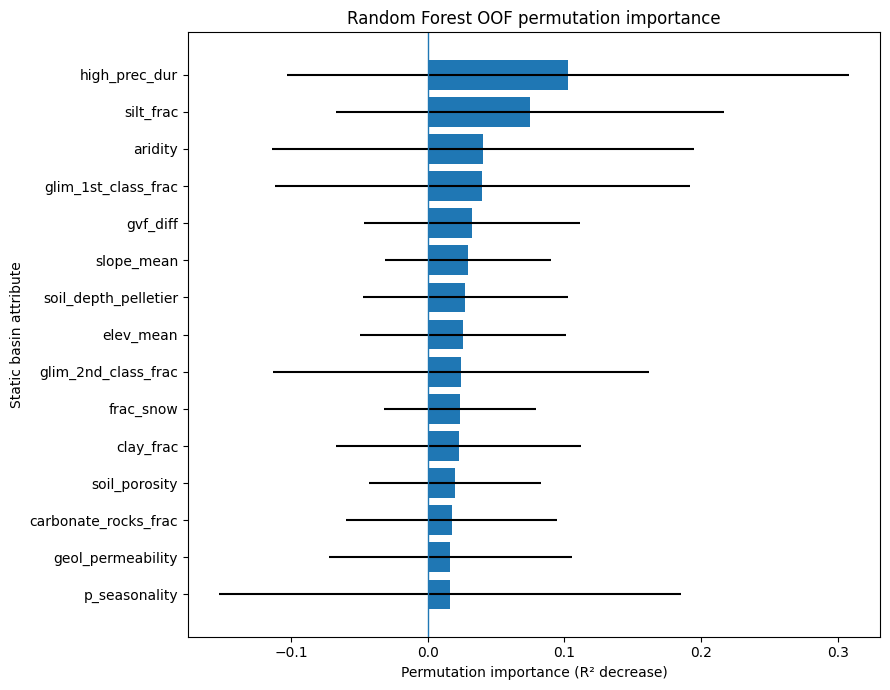

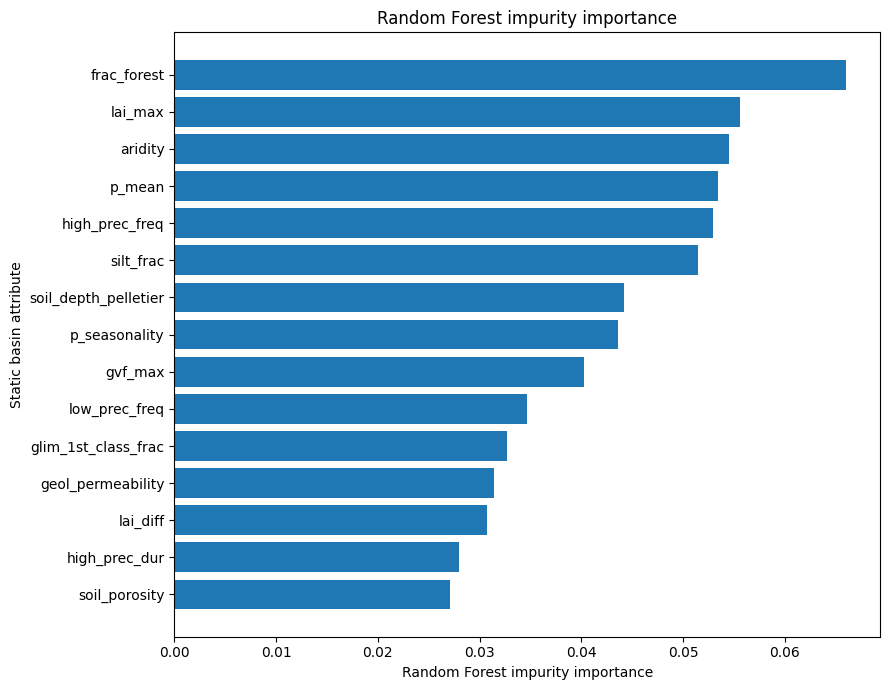


PARTIAL DEPENDENCE ANALYSIS
Plotting: aridity


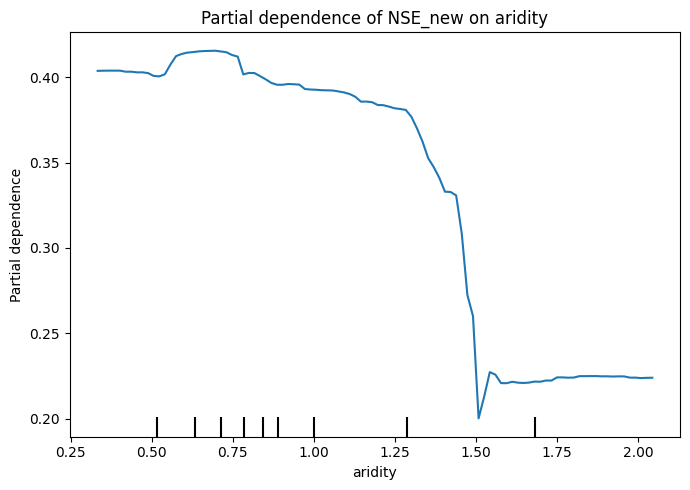

Plotting: p_mean


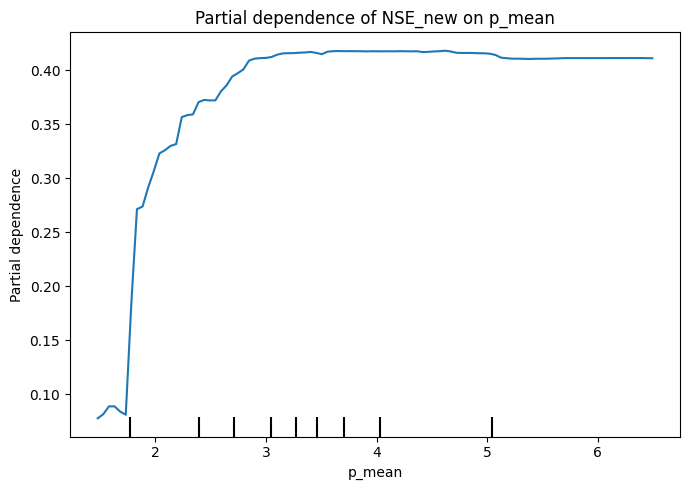

Plotting: low_prec_freq


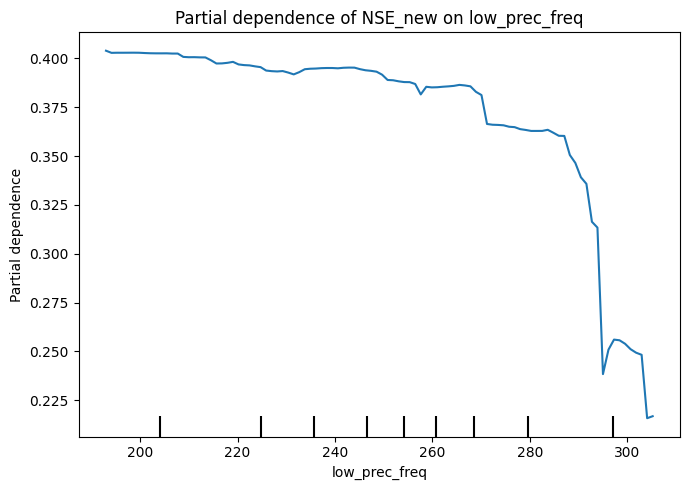

Plotting: high_prec_freq


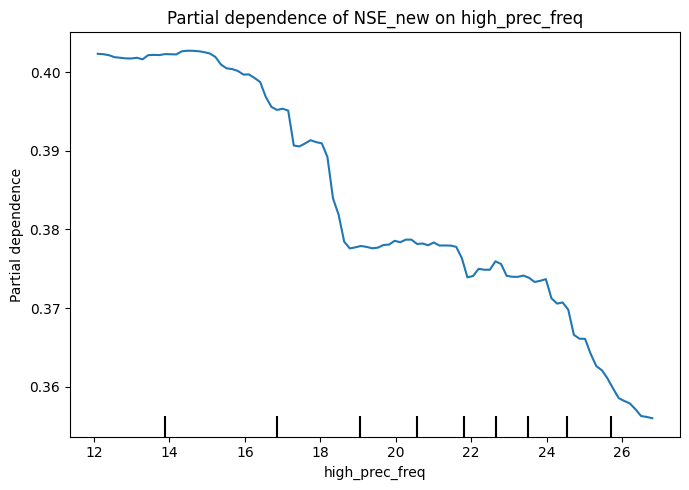

Plotting: frac_forest


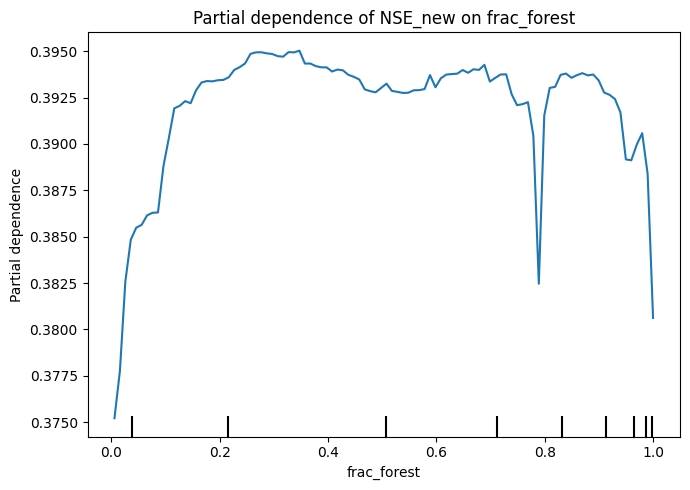

Plotting: gvf_max


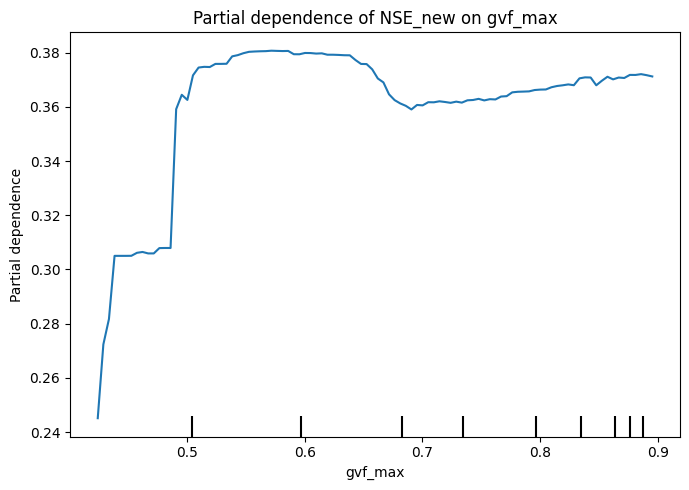


ATTRIBUTE VS NSE SCATTER PLOTS


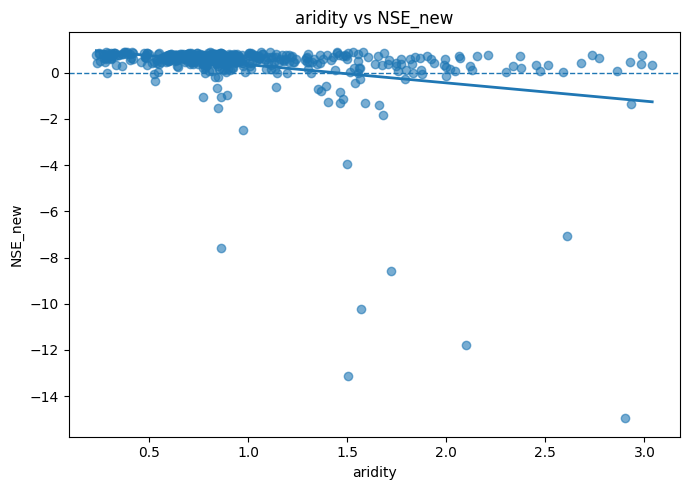

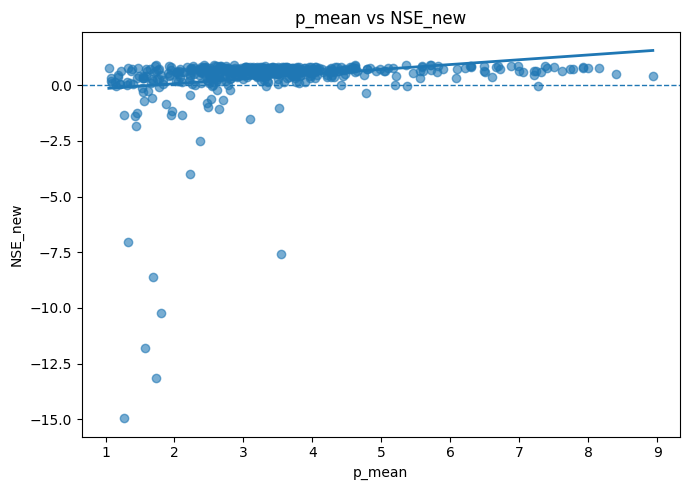

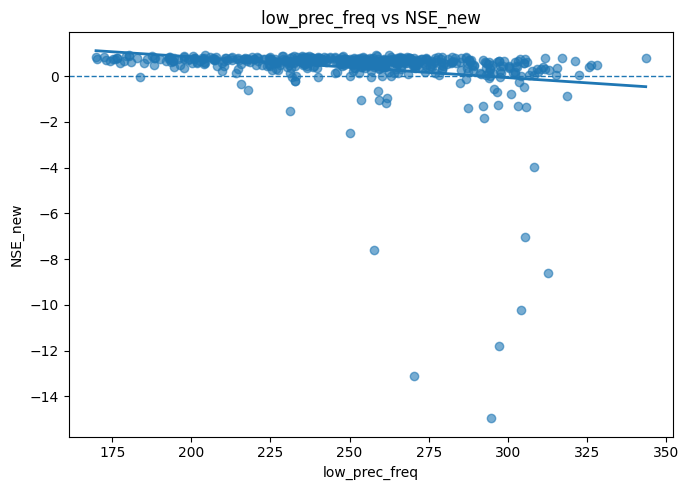

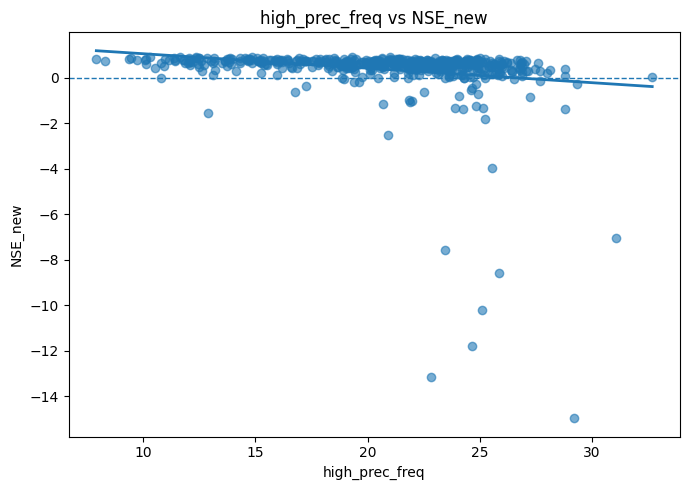

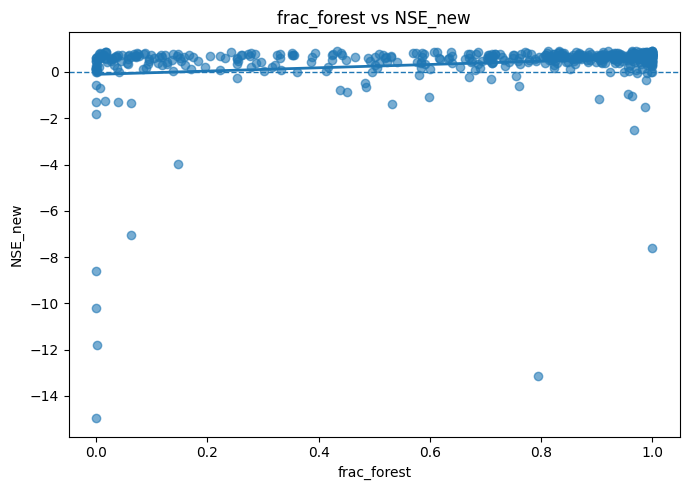

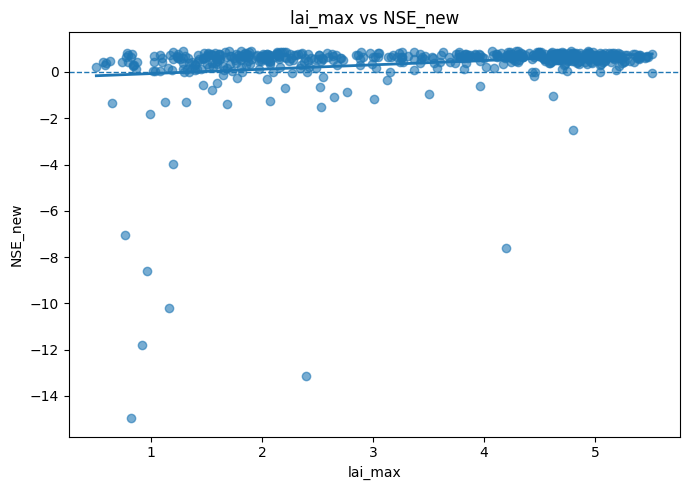

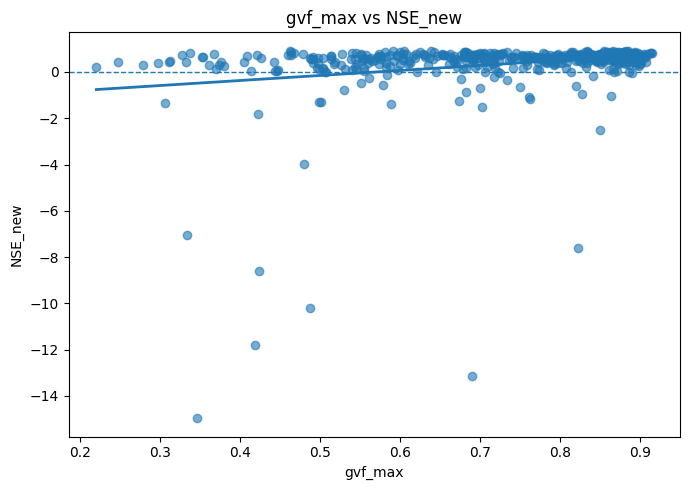

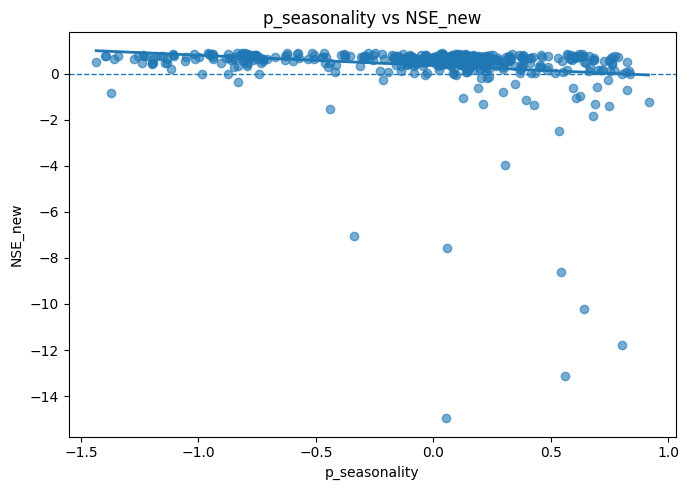


FINAL SUMMARY

Top attributes by Spearman correlation:
     Attribute  Spearman_r   Spearman_p
 low_prec_freq   -0.387372 1.865974e-20
high_prec_freq   -0.381409 7.859591e-20
       aridity   -0.342291 4.841742e-16
        p_mean    0.322828 2.408916e-14
 p_seasonality   -0.278202 6.805907e-11
       gvf_max    0.271817 1.900991e-10
   frac_forest    0.250385 4.928844e-09
  low_prec_dur   -0.229075 9.430350e-08
       lai_max    0.226199 1.375018e-07
     silt_frac    0.218806 3.543373e-07

Top attributes by OOF permutation importance:
           Attribute      Mean      Std   Median
       high_prec_dur  0.102376 0.205463 0.013262
           silt_frac  0.074637 0.141793 0.015353
         frac_forest -0.068181 0.274619 0.012662
             aridity  0.040512 0.154491 0.025994
 glim_1st_class_frac  0.039946 0.152010 0.012732
            gvf_diff  0.032341 0.078977 0.003325
             gvf_max -0.030368 0.165461 0.004481
             lai_max -0.030101 0.190589 0.014365
          slope_

In [50]:
# ============================================================
# STATIC BASIN ATTRIBUTE INFLUENCE ON NSE_NEW
#
# DATA:
#   df = DataFrame containing 531 basins
#
# TARGET:
#   NSE_new
#
# ANALYSIS:
#   1. Data quality checks
#   2. Pearson + Spearman correlation
#   3. Predictor multicollinearity
#   4. Robustness / sensitivity analysis
#      - All basins
#      - NSE >= -2
#      - NSE >= -5
#   5. Repeated 10-fold CV
#   6. Dummy / Ridge / Random Forest / Extra Trees
#   7. Pooled OOF predictions
#   8. OOF permutation importance
#   9. RF impurity importance
#  10. NSE performance groups
#  11. Group-wise attribute statistics
#  12. RF classification
#  13. Classification permutation importance
#  14. Partial dependence plots
#
# NOTHING IS SAVED TO DISK
# ============================================================


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import pearsonr, spearmanr

from sklearn.model_selection import (
    RepeatedKFold,
    StratifiedKFold
)

from sklearn.dummy import DummyRegressor

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import Ridge

from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    RandomForestClassifier
)

from sklearn.inspection import (
    permutation_importance,
    PartialDependenceDisplay
)

from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report
)


# ============================================================
# SETTINGS
# ============================================================

TARGET = "NSE_new"

RANDOM_STATE = 111111

N_SPLITS = 10
N_REPEATS = 5

N_ESTIMATORS = 500

# Thresholds for robustness analysis
ROBUSTNESS_THRESHOLDS = {
    "All basins": None,
    "NSE >= -5": -5,
    "NSE >= -2": -2
}


# ============================================================
# STATIC ATTRIBUTES
# ============================================================

ATTRIBUTE_COLUMNS = [
    "p_mean",
    "pet_mean",
    "p_seasonality",
    "frac_snow",
    "aridity",
    "high_prec_freq",
    "high_prec_dur",
    "low_prec_freq",
    "low_prec_dur",
    "elev_mean",
    "slope_mean",
    "area_gages2",
    "frac_forest",
    "lai_max",
    "lai_diff",
    "gvf_max",
    "gvf_diff",
    "dom_land_cover_frac",
    "dom_land_cover",
    "root_depth_50",
    "soil_depth_pelletier",
    "soil_depth_statsgo",
    "soil_porosity",
    "soil_conductivity",
    "max_water_content",
    "sand_frac",
    "silt_frac",
    "clay_frac",
    "geol_1st_class",
    "glim_1st_class_frac",
    "geol_2nd_class",
    "glim_2nd_class_frac",
    "carbonate_rocks_frac",
    "geol_porostiy",
    "geol_permeability"
]


# ============================================================
# CHECK THAT DATA EXIST
# ============================================================

if "df" not in globals():
    raise NameError(
        "DataFrame 'df' is not defined. "
        "Load your dataframe into df before running this script."
    )


print("\n" + "=" * 80)
print("STATIC ATTRIBUTE INFLUENCE ANALYSIS")
print("=" * 80)


# ============================================================
# BASIC DATA CHECKS
# ============================================================

print("\nDATASET SHAPE")
print("-" * 80)
print(df.shape)


missing_columns = [
    c for c in ATTRIBUTE_COLUMNS + [TARGET]
    if c not in df.columns
]

if len(missing_columns) > 0:
    raise ValueError(
        "The following required columns are missing:\n"
        + "\n".join(missing_columns)
    )


# Work on a copy
data = df[ATTRIBUTE_COLUMNS + [TARGET]].copy()


# Convert everything to numeric
for col in ATTRIBUTE_COLUMNS + [TARGET]:
    data[col] = pd.to_numeric(data[col], errors="coerce")


print("\nMISSING VALUES")
print("-" * 80)

missing = data.isna().sum()
print(missing[missing > 0])

if missing.sum() == 0:
    print("No missing values.")


# Remove rows with missing values
data = data.dropna().reset_index(drop=True)


print("\nFINAL DATASET")
print("-" * 80)
print("Number of basins:", len(data))
print("Number of predictors:", len(ATTRIBUTE_COLUMNS))


# ============================================================
# TARGET DISTRIBUTION
# ============================================================

y_all = data[TARGET].values


print("\n" + "=" * 80)
print("NSE_NEW DISTRIBUTION")
print("=" * 80)

print(
    data[TARGET].describe(
        percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    )
)


print("\nNegative NSE counts")
print("-" * 80)

print("NSE < 0 :", np.sum(y_all < 0))
print("NSE < -1:", np.sum(y_all < -1))
print("NSE < -2:", np.sum(y_all < -2))
print("NSE < -5:", np.sum(y_all < -5))
print("NSE < -10:", np.sum(y_all < -10))


print("\nLowest NSE basins")
print("-" * 80)

if "GAGE_ID" in df.columns:
    low_ids = (
        df.loc[data.index, ["GAGE_ID", TARGET]]
        .sort_values(TARGET)
        .head(20)
    )
    print(low_ids)
else:
    print(
        data[[TARGET]]
        .sort_values(TARGET)
        .head(20)
    )


# ============================================================
# CORRELATION ANALYSIS
# ============================================================

print("\n" + "=" * 80)
print("PEARSON AND SPEARMAN CORRELATION WITH NSE_NEW")
print("=" * 80)


correlation_results = []

for col in ATTRIBUTE_COLUMNS:

    x = data[col].values
    y = data[TARGET].values

    pearson_r, pearson_p = pearsonr(x, y)
    spearman_r, spearman_p = spearmanr(x, y)

    correlation_results.append({
        "Attribute": col,
        "Pearson_r": pearson_r,
        "Pearson_p": pearson_p,
        "Spearman_r": spearman_r,
        "Spearman_p": spearman_p,
        "Abs_Pearson": abs(pearson_r),
        "Abs_Spearman": abs(spearman_r)
    })


correlation_df = pd.DataFrame(correlation_results)


correlation_df = correlation_df.sort_values(
    "Abs_Spearman",
    ascending=False
)


print(
    correlation_df[
        [
            "Attribute",
            "Pearson_r",
            "Pearson_p",
            "Spearman_r",
            "Spearman_p"
        ]
    ].to_string(index=False)
)


# ============================================================
# TOP CORRELATIONS
# ============================================================

print("\nTOP 15 ATTRIBUTES BY ABSOLUTE SPEARMAN CORRELATION")
print("-" * 80)

print(
    correlation_df.head(15)[
        [
            "Attribute",
            "Pearson_r",
            "Spearman_r",
            "Spearman_p"
        ]
    ].to_string(index=False)
)


# ============================================================
# HIGH CORRELATION AMONG PREDICTORS
# ============================================================

print("\n" + "=" * 80)
print("HIGHLY CORRELATED PREDICTOR PAIRS")
print("=" * 80)


X_attributes = data[ATTRIBUTE_COLUMNS]

predictor_corr = X_attributes.corr(method="pearson")


high_corr_pairs = []

for i in range(len(ATTRIBUTE_COLUMNS)):

    for j in range(i + 1, len(ATTRIBUTE_COLUMNS)):

        c1 = ATTRIBUTE_COLUMNS[i]
        c2 = ATTRIBUTE_COLUMNS[j]

        corr_value = predictor_corr.loc[c1, c2]

        if abs(corr_value) >= 0.80:

            high_corr_pairs.append({
                "Attribute_1": c1,
                "Attribute_2": c2,
                "Correlation": corr_value,
                "Abs_Correlation": abs(corr_value)
            })


high_corr_df = pd.DataFrame(high_corr_pairs)


if len(high_corr_df) > 0:

    high_corr_df = high_corr_df.sort_values(
        "Abs_Correlation",
        ascending=False
    )

    print(high_corr_df.to_string(index=False))

else:
    print("No predictor pairs with |r| >= 0.80.")


# ============================================================
# FUNCTION:
# REGRESSION MODELS
# ============================================================

def run_regression_analysis(
    analysis_data,
    analysis_name,
    random_state=111111
):

    print("\n\n" + "#" * 80)
    print("REGRESSION ANALYSIS:", analysis_name)
    print("#" * 80)

    X = analysis_data[ATTRIBUTE_COLUMNS].copy()
    y = analysis_data[TARGET].values

    print("\nNumber of basins:", len(analysis_data))
    print("NSE mean:", np.mean(y))
    print("NSE median:", np.median(y))
    print("NSE std:", np.std(y))
    print("NSE min:", np.min(y))
    print("NSE max:", np.max(y))


    # --------------------------------------------------------
    # MODELS
    # --------------------------------------------------------

    models = {

        "Dummy Mean": DummyRegressor(
            strategy="mean"
        ),

        "Ridge": Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "model",
                Ridge(
                    alpha=10.0
                )
            )
        ]),

        "Random Forest": RandomForestRegressor(
            n_estimators=N_ESTIMATORS,
            random_state=random_state,
            n_jobs=-1,
            max_features="sqrt",
            min_samples_leaf=3
        ),

        "Extra Trees": ExtraTreesRegressor(
            n_estimators=N_ESTIMATORS,
            random_state=random_state,
            n_jobs=-1,
            max_features="sqrt",
            min_samples_leaf=3
        )
    }


    # --------------------------------------------------------
    # REPEATED K-FOLD
    # --------------------------------------------------------

    cv = RepeatedKFold(
        n_splits=N_SPLITS,
        n_repeats=N_REPEATS,
        random_state=random_state
    )


    results = []

    oof_predictions = {
        model_name: []
        for model_name in models
    }

    oof_observations = {
        model_name: []
        for model_name in models
    }


    print("\nRepeated CV results")
    print("-" * 80)


    for model_name, model in models.items():

        fold_r2 = []
        fold_rmse = []

        for fold_number, (train_idx, test_idx) in enumerate(
            cv.split(X),
            start=1
        ):

            X_train = X.iloc[train_idx]
            X_test = X.iloc[test_idx]

            y_train = y[train_idx]
            y_test = y[test_idx]


            model.fit(
                X_train,
                y_train
            )


            prediction = model.predict(
                X_test
            )


            r2 = r2_score(
                y_test,
                prediction
            )

            rmse = np.sqrt(
                mean_squared_error(
                    y_test,
                    prediction
                )
            )


            fold_r2.append(r2)
            fold_rmse.append(rmse)


            oof_predictions[model_name].extend(
                prediction
            )

            oof_observations[model_name].extend(
                y_test
            )


        results.append({
            "Model": model_name,
            "R2_mean": np.mean(fold_r2),
            "R2_std": np.std(fold_r2),
            "RMSE_mean": np.mean(fold_rmse),
            "RMSE_std": np.std(fold_rmse)
        })


    results_df = pd.DataFrame(results)


    print(
        results_df.to_string(index=False)
    )


    # --------------------------------------------------------
    # POOLED OOF PERFORMANCE
    # --------------------------------------------------------

    print("\nPooled OOF performance")
    print("-" * 80)


    pooled_results = []


    for model_name in models:

        pred = np.asarray(
            oof_predictions[model_name]
        )

        obs = np.asarray(
            oof_observations[model_name]
        )


        pooled_r2 = r2_score(
            obs,
            pred
        )

        pooled_rmse = np.sqrt(
            mean_squared_error(
                obs,
                pred
            )
        )


        pooled_results.append({
            "Model": model_name,
            "OOF_R2": pooled_r2,
            "OOF_RMSE": pooled_rmse
        })


    pooled_df = pd.DataFrame(
        pooled_results
    )


    print(
        pooled_df.to_string(index=False)
    )


    # --------------------------------------------------------
    # OOF PERMUTATION IMPORTANCE
    # --------------------------------------------------------

    print("\nOOF permutation importance")
    print("-" * 80)

    rf = RandomForestRegressor(
        n_estimators=N_ESTIMATORS,
        random_state=random_state,
        n_jobs=-1,
        max_features="sqrt",
        min_samples_leaf=3
    )


    importance_records = []


    for fold_number, (train_idx, test_idx) in enumerate(
        cv.split(X),
        start=1
    ):

        X_train = X.iloc[train_idx]
        X_test = X.iloc[test_idx]

        y_train = y[train_idx]
        y_test = y[test_idx]


        rf.fit(
            X_train,
            y_train
        )


        permutation = permutation_importance(
            rf,
            X_test,
            y_test,
            scoring="r2",
            n_repeats=10,
            random_state=random_state + fold_number,
            n_jobs=-1
        )


        for feature_idx, feature in enumerate(
            ATTRIBUTE_COLUMNS
        ):

            for repeat_idx in range(
                permutation.importances.shape[1]
            ):

                importance_records.append({
                    "Fold": fold_number,
                    "Attribute": feature,
                    "Importance": permutation.importances[
                        feature_idx,
                        repeat_idx
                    ]
                })


    importance_long = pd.DataFrame(
        importance_records
    )


    importance_summary = (
        importance_long
        .groupby("Attribute")["Importance"]
        .agg(
            Mean="mean",
            Std="std",
            Median="median"
        )
        .reset_index()
    )


    importance_summary["Abs_Mean"] = (
        importance_summary["Mean"].abs()
    )


    importance_summary = (
        importance_summary
        .sort_values(
            "Abs_Mean",
            ascending=False
        )
    )


    print(
        importance_summary[
            [
                "Attribute",
                "Mean",
                "Std",
                "Median"
            ]
        ].head(20).to_string(index=False)
    )


    # --------------------------------------------------------
    # FIT FINAL RF
    # --------------------------------------------------------

    final_rf = RandomForestRegressor(
        n_estimators=N_ESTIMATORS,
        random_state=random_state,
        n_jobs=-1,
        max_features="sqrt",
        min_samples_leaf=3
    )


    final_rf.fit(
        X,
        y
    )


    # --------------------------------------------------------
    # IMPURITY IMPORTANCE
    # --------------------------------------------------------

    impurity_df = pd.DataFrame({
        "Attribute": ATTRIBUTE_COLUMNS,
        "Importance": final_rf.feature_importances_
    })


    impurity_df = impurity_df.sort_values(
        "Importance",
        ascending=False
    )


    print("\nRF impurity importance")
    print("-" * 80)

    print(
        impurity_df.head(20).to_string(
            index=False
        )
    )


    return {
        "cv_results": results_df,
        "pooled_results": pooled_df,
        "permutation_long": importance_long,
        "permutation_summary": importance_summary,
        "impurity": impurity_df,
        "final_model": final_rf
    }


# ============================================================
# ROBUSTNESS / SENSITIVITY ANALYSIS
# ============================================================

all_regression_results = {}


for analysis_name, threshold in ROBUSTNESS_THRESHOLDS.items():

    if threshold is None:

        subset = data.copy()

    else:

        subset = data[
            data[TARGET] >= threshold
        ].copy()

    subset = subset.reset_index(
        drop=True
    )


    all_regression_results[
        analysis_name
    ] = run_regression_analysis(
        subset,
        analysis_name,
        RANDOM_STATE
    )


# ============================================================
# COMPARE ROBUSTNESS RESULTS
# ============================================================

print("\n\n" + "=" * 80)
print("ROBUSTNESS COMPARISON")
print("=" * 80)


robustness_table = []


for analysis_name, result in all_regression_results.items():

    pooled = result["pooled_results"]

    rf_row = pooled[
        pooled["Model"] == "Random Forest"
    ].iloc[0]

    et_row = pooled[
        pooled["Model"] == "Extra Trees"
    ].iloc[0]


    robustness_table.append({
        "Dataset": analysis_name,
        "N_basins": (
            len(data)
            if analysis_name == "All basins"
            else len(
                data[
                    data[TARGET] >=
                    ROBUSTNESS_THRESHOLDS[
                        analysis_name
                    ]
                ]
            )
        ),
        "RF_OOF_R2": rf_row["OOF_R2"],
        "RF_OOF_RMSE": rf_row["OOF_RMSE"],
        "ET_OOF_R2": et_row["OOF_R2"],
        "ET_OOF_RMSE": et_row["OOF_RMSE"]
    })


robustness_df = pd.DataFrame(
    robustness_table
)


print(
    robustness_df.to_string(
        index=False
    )
)


# ============================================================
# COMPARE PERMUTATION IMPORTANCE ACROSS DATASETS
# ============================================================

print("\n" + "=" * 80)
print("TOP PERMUTATION IMPORTANCE ACROSS ROBUSTNESS CASES")
print("=" * 80)


for analysis_name, result in all_regression_results.items():

    print("\n" + analysis_name)
    print("-" * 80)

    print(
        result["permutation_summary"]
        .head(15)[
            [
                "Attribute",
                "Mean",
                "Std",
                "Median"
            ]
        ]
        .to_string(index=False)
    )


# ============================================================
# NSE PERFORMANCE GROUPS
# ============================================================

print("\n" + "=" * 80)
print("NSE PERFORMANCE GROUPS")
print("=" * 80)


def classify_nse(nse):

    if nse < 0:
        return "NSE < 0"

    elif nse < 0.3:
        return "0 <= NSE < 0.3"

    elif nse < 0.7:
        return "0.3 <= NSE < 0.7"

    else:
        return "NSE >= 0.7"


data["NSE_Group"] = data[TARGET].apply(
    classify_nse
)


group_order = [
    "NSE < 0",
    "0 <= NSE < 0.3",
    "0.3 <= NSE < 0.7",
    "NSE >= 0.7"
]


print(
    data["NSE_Group"]
    .value_counts()
    .reindex(group_order)
)


# ============================================================
# GROUP-WISE ATTRIBUTE MEANS
# ============================================================

group_means = (
    data
    .groupby("NSE_Group")[
        ATTRIBUTE_COLUMNS
    ]
    .mean()
    .reindex(group_order)
)


print("\n" + "=" * 80)
print("GROUP-WISE ATTRIBUTE MEANS")
print("=" * 80)

print(
    group_means.to_string()
)


# ============================================================
# STANDARDIZED GROUP MEANS
# ============================================================

print("\n" + "=" * 80)
print("STANDARDIZED GROUP MEANS")
print("=" * 80)


group_std = (
    data[ATTRIBUTE_COLUMNS]
    .std()
)


group_means_z = (
    group_means -
    data[ATTRIBUTE_COLUMNS].mean()
) / group_std


print(
    group_means_z.to_string()
)


# ============================================================
# BOXPLOTS FOR IMPORTANT ATTRIBUTES
# ============================================================

top_corr_attributes = (
    correlation_df
    .head(8)["Attribute"]
    .tolist()
)


for feature in top_corr_attributes:

    plt.figure(
        figsize=(8, 5)
    )

    data.boxplot(
        column=feature,
        by="NSE_Group",
        grid=False
    )

    plt.title(
        f"{feature} across NSE performance groups"
    )

    plt.suptitle("")

    plt.xlabel(
        "NSE performance group"
    )

    plt.ylabel(
        feature
    )

    plt.xticks(
        rotation=20
    )

    plt.tight_layout()

    plt.show()


# ============================================================
# RF CLASSIFICATION
# ============================================================

print("\n" + "=" * 80)
print("NSE PERFORMANCE CLASSIFICATION")
print("=" * 80)


X_class = data[ATTRIBUTE_COLUMNS]
y_class = data["NSE_Group"]


# Encode groups as integers
group_to_int = {
    group: i
    for i, group in enumerate(group_order)
}


y_class_int = y_class.map(
    group_to_int
).values


class_counts = pd.Series(
    y_class_int
).value_counts().sort_index()


print("\nClass counts")
print("-" * 80)

for class_id, count in class_counts.items():

    print(
        f"{group_order[class_id]}: {count}"
    )


# ------------------------------------------------------------
# STRATIFIED CV
# ------------------------------------------------------------

classifier = RandomForestClassifier(
    n_estimators=N_ESTIMATORS,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    max_features="sqrt",
    min_samples_leaf=3,
    class_weight="balanced"
)


class_cv = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=RANDOM_STATE
)


classification_results = []

all_true = []
all_pred = []


for fold_number, (
    train_idx,
    test_idx
) in enumerate(
    class_cv.split(
        X_class,
        y_class_int
    ),
    start=1
):

    X_train = X_class.iloc[
        train_idx
    ]

    X_test = X_class.iloc[
        test_idx
    ]

    y_train = y_class_int[
        train_idx
    ]

    y_test = y_class_int[
        test_idx
    ]


    classifier.fit(
        X_train,
        y_train
    )


    prediction = classifier.predict(
        X_test
    )


    accuracy = accuracy_score(
        y_test,
        prediction
    )

    balanced_acc = balanced_accuracy_score(
        y_test,
        prediction
    )

    f1 = f1_score(
        y_test,
        prediction,
        average="macro"
    )


    classification_results.append({
        "Fold": fold_number,
        "Accuracy": accuracy,
        "Balanced_Accuracy": balanced_acc,
        "Macro_F1": f1
    })


    all_true.extend(
        y_test
    )

    all_pred.extend(
        prediction
    )


classification_results_df = pd.DataFrame(
    classification_results
)


print(
    classification_results_df[
        [
            "Accuracy",
            "Balanced_Accuracy",
            "Macro_F1"
        ]
    ].agg(
        ["mean", "std"]
    )
)


# ============================================================
# POOLED CLASSIFICATION RESULTS
# ============================================================

all_true = np.asarray(
    all_true
)

all_pred = np.asarray(
    all_pred
)


print("\nPooled classification performance")
print("-" * 80)

print(
    "Accuracy:",
    accuracy_score(
        all_true,
        all_pred
    )
)

print(
    "Balanced accuracy:",
    balanced_accuracy_score(
        all_true,
        all_pred
    )
)

print(
    "Macro F1:",
    f1_score(
        all_true,
        all_pred,
        average="macro"
    )
)


# ============================================================
# CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    all_true,
    all_pred
)


cm_df = pd.DataFrame(
    cm,
    index=group_order,
    columns=group_order
)


print("\nConfusion matrix")
print("-" * 80)

print(cm_df)


print("\nClassification report")
print("-" * 80)

print(
    classification_report(
        all_true,
        all_pred,
        target_names=group_order,
        zero_division=0
    )
)


# ============================================================
# CLASSIFICATION PERMUTATION IMPORTANCE
# ============================================================

classifier_final = RandomForestClassifier(
    n_estimators=N_ESTIMATORS,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    max_features="sqrt",
    min_samples_leaf=3,
    class_weight="balanced"
)


classifier_final.fit(
    X_class,
    y_class_int
)


class_perm = permutation_importance(
    classifier_final,
    X_class,
    y_class_int,
    scoring="balanced_accuracy",
    n_repeats=30,
    random_state=RANDOM_STATE,
    n_jobs=-1
)


classification_importance_df = pd.DataFrame({
    "Attribute": ATTRIBUTE_COLUMNS,
    "Importance_Mean": class_perm.importances_mean,
    "Importance_Std": class_perm.importances_std
})


classification_importance_df = (
    classification_importance_df
    .sort_values(
        "Importance_Mean",
        ascending=False
    )
)


print("\n" + "=" * 80)
print("CLASSIFICATION PERMUTATION IMPORTANCE")
print("=" * 80)


print(
    classification_importance_df
    .head(20)
    .to_string(index=False)
)


# ============================================================
# REGRESSION IMPORTANCE PLOTS
# ============================================================

print("\n" + "=" * 80)
print("GENERATING IMPORTANCE PLOTS")
print("=" * 80)


# ------------------------------------------------------------
# Plot permutation importance for all basins
# ------------------------------------------------------------

importance_all = (
    all_regression_results[
        "All basins"
    ]["permutation_summary"]
    .copy()
)


plot_df = (
    importance_all
    .sort_values(
        "Mean",
        ascending=True
    )
    .tail(15)
)


plt.figure(
    figsize=(9, 7)
)


plt.barh(
    plot_df["Attribute"],
    plot_df["Mean"],
    xerr=plot_df["Std"]
)


plt.axvline(
    0,
    linewidth=1
)


plt.xlabel(
    "Permutation importance (R² decrease)"
)

plt.ylabel(
    "Static basin attribute"
)

plt.title(
    "Random Forest OOF permutation importance"
)

plt.tight_layout()

plt.show()


# ============================================================
# IMPURITY IMPORTANCE PLOT
# ============================================================

impurity_all = (
    all_regression_results[
        "All basins"
    ]["impurity"]
    .copy()
)


plot_impurity = (
    impurity_all
    .sort_values(
        "Importance",
        ascending=True
    )
    .tail(15)
)


plt.figure(
    figsize=(9, 7)
)


plt.barh(
    plot_impurity["Attribute"],
    plot_impurity["Importance"]
)


plt.xlabel(
    "Random Forest impurity importance"
)

plt.ylabel(
    "Static basin attribute"
)

plt.title(
    "Random Forest impurity importance"
)

plt.tight_layout()

plt.show()


# ============================================================
# PARTIAL DEPENDENCE
# ============================================================

print("\n" + "=" * 80)
print("PARTIAL DEPENDENCE ANALYSIS")
print("=" * 80)


final_rf = (
    all_regression_results[
        "All basins"
    ]["final_model"]
)


# Use the strongest stable correlation variables
pd_features = [
    "aridity",
    "p_mean",
    "low_prec_freq",
    "high_prec_freq",
    "frac_forest",
    "gvf_max"
]


for feature in pd_features:

    if feature not in ATTRIBUTE_COLUMNS:
        continue

    print(
        "Plotting:",
        feature
    )

    fig, ax = plt.subplots(
        figsize=(7, 5)
    )


    PartialDependenceDisplay.from_estimator(
        final_rf,
        data[ATTRIBUTE_COLUMNS],
        [feature],
        ax=ax
    )


    plt.title(
        f"Partial dependence of NSE_new on {feature}"
    )

    plt.tight_layout()

    plt.show()


# ============================================================
# ATTRIBUTE-LEVEL SCATTER PLOTS
# ============================================================

print("\n" + "=" * 80)
print("ATTRIBUTE VS NSE SCATTER PLOTS")
print("=" * 80)


scatter_features = [
    "aridity",
    "p_mean",
    "low_prec_freq",
    "high_prec_freq",
    "frac_forest",
    "lai_max",
    "gvf_max",
    "p_seasonality"
]


for feature in scatter_features:

    plt.figure(
        figsize=(7, 5)
    )


    plt.scatter(
        data[feature],
        data[TARGET],
        alpha=0.6
    )


    # Linear trend
    x = data[feature].values
    y = data[TARGET].values

    valid = (
        np.isfinite(x) &
        np.isfinite(y)
    )

    if valid.sum() > 2:

        slope, intercept = np.polyfit(
            x[valid],
            y[valid],
            1
        )

        x_line = np.linspace(
            np.min(x[valid]),
            np.max(x[valid]),
            100
        )

        y_line = (
            slope * x_line +
            intercept
        )


        plt.plot(
            x_line,
            y_line,
            linewidth=2
        )


    plt.axhline(
        0,
        linestyle="--",
        linewidth=1
    )


    plt.xlabel(
        feature
    )

    plt.ylabel(
        "NSE_new"
    )

    plt.title(
        f"{feature} vs NSE_new"
    )

    plt.tight_layout()

    plt.show()


# ============================================================
# SUMMARY TABLE
# ============================================================

print("\n" + "=" * 80)
print("FINAL SUMMARY")
print("=" * 80)


print("\nTop attributes by Spearman correlation:")
print(
    correlation_df.head(10)[
        [
            "Attribute",
            "Spearman_r",
            "Spearman_p"
        ]
    ].to_string(index=False)
)


print("\nTop attributes by OOF permutation importance:")
print(
    all_regression_results[
        "All basins"
    ]["permutation_summary"]
    .head(10)[
        [
            "Attribute",
            "Mean",
            "Std",
            "Median"
        ]
    ].to_string(index=False)
)


print("\nTop attributes by RF impurity importance:")
print(
    all_regression_results[
        "All basins"
    ]["impurity"]
    .head(10)
    .to_string(index=False)
)


print("\nTop attributes by NSE-group classification:")
print(
    classification_importance_df
    .head(10)
    .to_string(index=False)
)


print("\n" + "=" * 80)
print("ANALYSIS COMPLETE")
print("=" * 80)